# **RANDOM FOREST REGRESSION**



 **1. Import thư viện và đọc dữ liệu**



In [ ]:
# Import dữ liệu
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.inspection import PartialDependenceDisplay
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [ ]:
# Kết nối Google Drive để đọc file dữ liệu
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Đọc dữ liệu
X_train = pd.read_csv("/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/X_train.csv")
X_test = pd.read_csv("/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/X_test.csv")
# Dùng .squeeze() để chuyển y về dạng Series (mảng 1 chiều) chuẩn
y_train = pd.read_csv("/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/y_train.csv").squeeze()
y_test = pd.read_csv("/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/DATA/y_test.csv").squeeze()

# Kiểm tra nhanh kích thước dữ liệu
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (25970, 20)
X_test shape : (6493, 20)
y_train shape: (25970,)
y_test shape : (6493,)


**2. Tiền xử lý dữ liệu (Encoding)**




In [ ]:
# Phân loại biến dựa trên ý nghĩa nghiệp vụ
# cat_cols: biến phân loại (ordinal / nominal)
# num_cols: biến số

cat_cols = [
    'type_of_order',
    'type_of_vehicle',
    'festival',
    'weather_traffic',
    'traffic_city',
    'vehicle_condition' ,
    'multiple_deliveries',
    'is_weekend'
]

num_cols = [
    'delivery_person_age',
    'delivery_person_ratings',
    'prep_time',
    'distance_km',
    'hour_sin', 'hour_cos',
    'dow_sin', 'dow_cos',
    'month_sin', 'month_cos',
    'prev_time_taken',
    'rolling_avg_city'
]
# Pipeline tiền xử lý
preprocess = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ]
)

**3. Xây dựng Random Forest Baseline**

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocess = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ]
)

In [ ]:
rf_pipeline = Pipeline(steps=[
    ('preprocess', preprocess),
    ('model', RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['delivery_person_age',
                                                   'delivery_person_ratings',
                                                   'prep_time', 'distance_km',
                                                   'hour_sin', 'hour_cos',
                                                   'dow_sin', 'dow_cos',
                                                   'month_sin', 'month_cos',
                                                   'prev_time_taken',
                                                   'rolling_avg_city']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   Simp...r(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['type_of_order',
                                                   'type_of_vehicle',
                                                   'festival',
                                                   'weather_traffic',
                                                   'traffic_city',
                                                   'vehicle_condition',
                                                   'multiple_deliveries',
                                                   'is_weekend'])])),
                ('model',
                 RandomForestRegressor(max_depth=12, min_samples_leaf=4,
                                       min_samples_split=10, n_estimators=200,
                                       n_jobs=-1, random_state=42))])

**4. Đánh giá mô hình Random Forest (Baseline)**

In [ ]:
y_pred_train = rf_pipeline.predict(X_train)
y_pred_test  = rf_pipeline.predict(X_test)

def evaluate_model(y_true, y_pred, name="DATA"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"--- {name} ---")
    print(f"MAE : {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²  : {r2:.4f}")
    print("-"*30)

evaluate_model(y_train, y_pred_train, "TRAIN")
evaluate_model(y_test, y_pred_test, "TEST")


--- TRAIN ---
MAE : 2.9085
RMSE: 3.6809
R²  : 0.8461
------------------------------
--- TEST ---
MAE : 3.3022
RMSE: 4.0995
R²  : 0.8114
------------------------------


**5. Tinh chỉnh mô hình Random Forest**


In [ ]:
#Thiết lập không gian tham số
param_dist = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [8, 10, 12, 15, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [2,4,6,8],
    'model__max_features': ['sqrt', 'log2', None]
    }
# Thực hiện Randomized Search
rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1
)
rf_random.fit(X_train, y_train)
# Mô hình Random Forest tối ưu
rf_best = rf_random.best_estimator_

print("=== RANDOM FOREST SAU TUNING ===")
print("Best parameters:")
print(rf_random.best_params_)

=== RANDOM FOREST SAU TUNING ===
Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': None, 'model__max_depth': 20}


**6. Đánh giá mô hình sau tuning**

In [ ]:
y_pred_train_best = rf_best.predict(X_train)
y_pred_test_best  = rf_best.predict(X_test)

evaluate_model(y_train, y_pred_train_best, "TRAIN (Tuned RF)")
evaluate_model(y_test, y_pred_test_best, "TEST (Tuned RF)")
print("Overfitting gap:",
      r2_score(y_train,y_pred_train_best) -
      r2_score(y_test,y_pred_test_best))

--- TRAIN (Tuned RF) ---
MAE : 2.1744
RMSE: 2.7169
R²  : 0.9162
------------------------------
--- TEST (Tuned RF) ---
MAE : 3.1242
RMSE: 3.8579
R²  : 0.8330
------------------------------
Overfitting gap: 0.08317184201678085


**7. Biểu đồ Thực tế vs Dự báo**

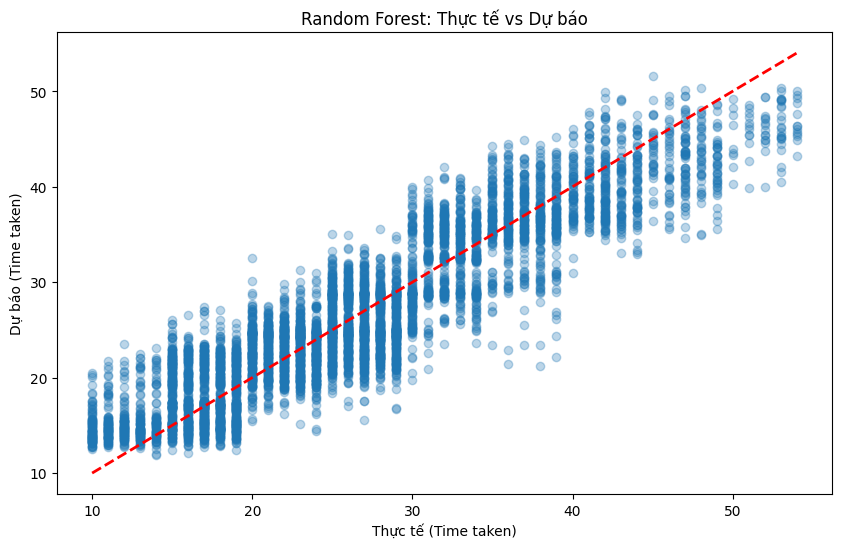

In [ ]:
#Actual vs Predicted

plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred_test_best, alpha=0.3)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', lw=2)
plt.xlabel("Thực tế (Time taken)")
plt.ylabel("Dự báo (Time taken)")
plt.title("Random Forest: Thực tế vs Dự báo")
plt.show()


**8. Phân tích sai số (Residual Analysis)**

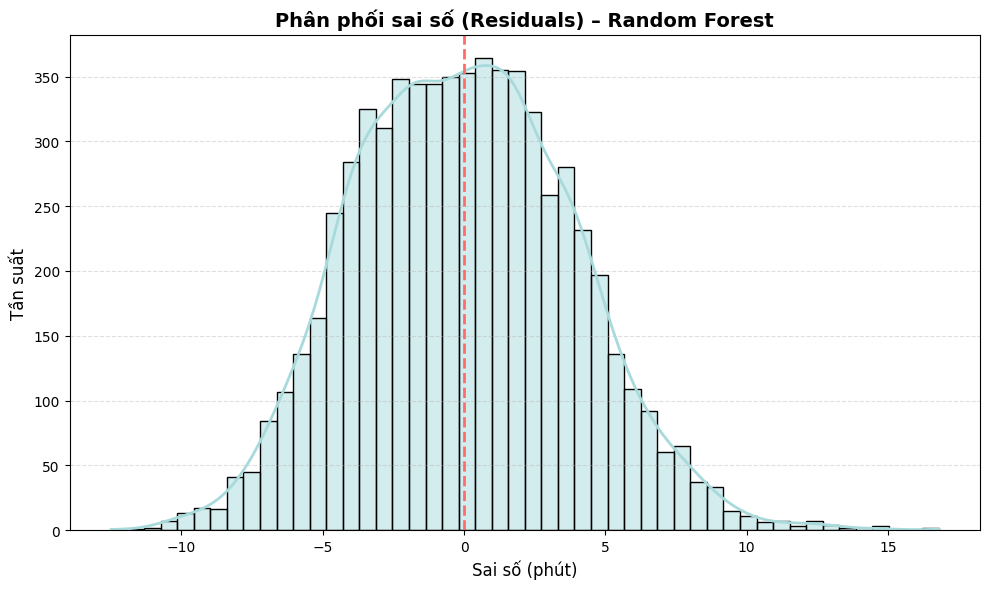

Mean residual: -0.026050682179570947
Std residual : 3.8581207956137233


In [ ]:
residuals = y_test - y_pred_test_best

plt.figure(figsize=(10,6))

sns.histplot(
    residuals,
    kde=True,
    bins=50,
    color='#A8DADC',          # màu cột
    edgecolor='black',
    line_kws={'color':'#2F4B7C','linewidth':2}  # màu đường KDE
)

plt.axvline(0,
            color='#FF6B6B',
            linestyle='--',
            linewidth=2)

plt.title("Phân phối sai số (Residuals) – Random Forest",
          fontsize=14,
          fontweight='bold')

plt.xlabel("Sai số (phút)",fontsize=12)
plt.ylabel("Tần suất",fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print("Mean residual:", residuals.mean())
print("Std residual :", residuals.std())

**9. Feature Importance (Model-based)**


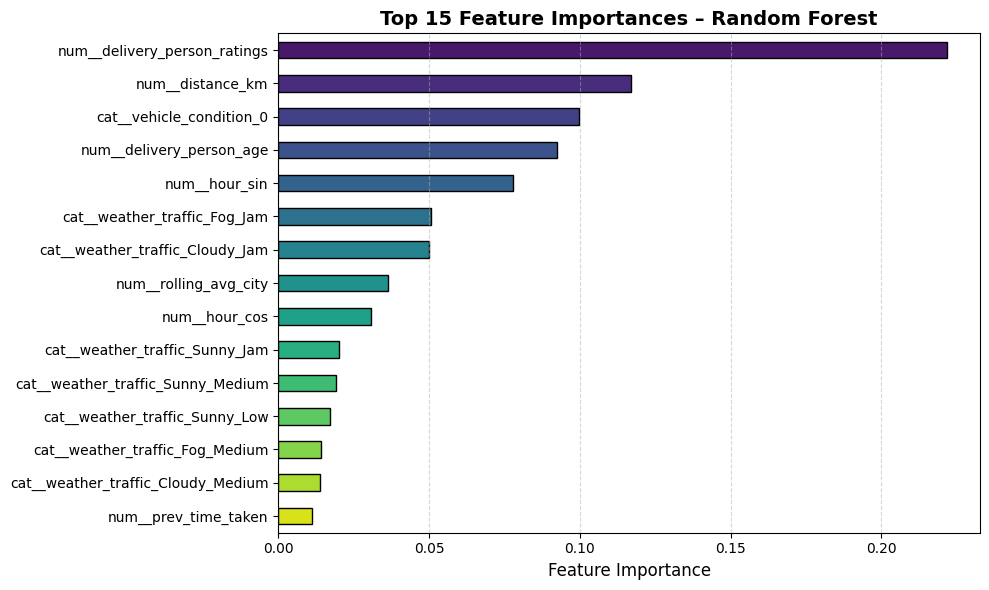

In [ ]:
rf_model = rf_best.named_steps['model']
feature_names = rf_best.named_steps['preprocess'].get_feature_names_out()

importances = rf_model.feature_importances_

feat_imp = pd.Series(importances, index=feature_names)\
             .sort_values(ascending=False)

plt.figure(figsize=(10,6))
colors = sns.color_palette("viridis",15)
feat_imp.head(15).plot(
    kind='barh',
    color=colors,
    edgecolor='black'
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance",fontsize=12)
plt.title("Top 15 Feature Importances – Random Forest",
          fontsize=14,
          fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**10. Permutation Importance (Xác nhận lại Feature Importance)**

🚀 Đang tính Permutation Importance trên Pipeline (có thể mất vài phút)...


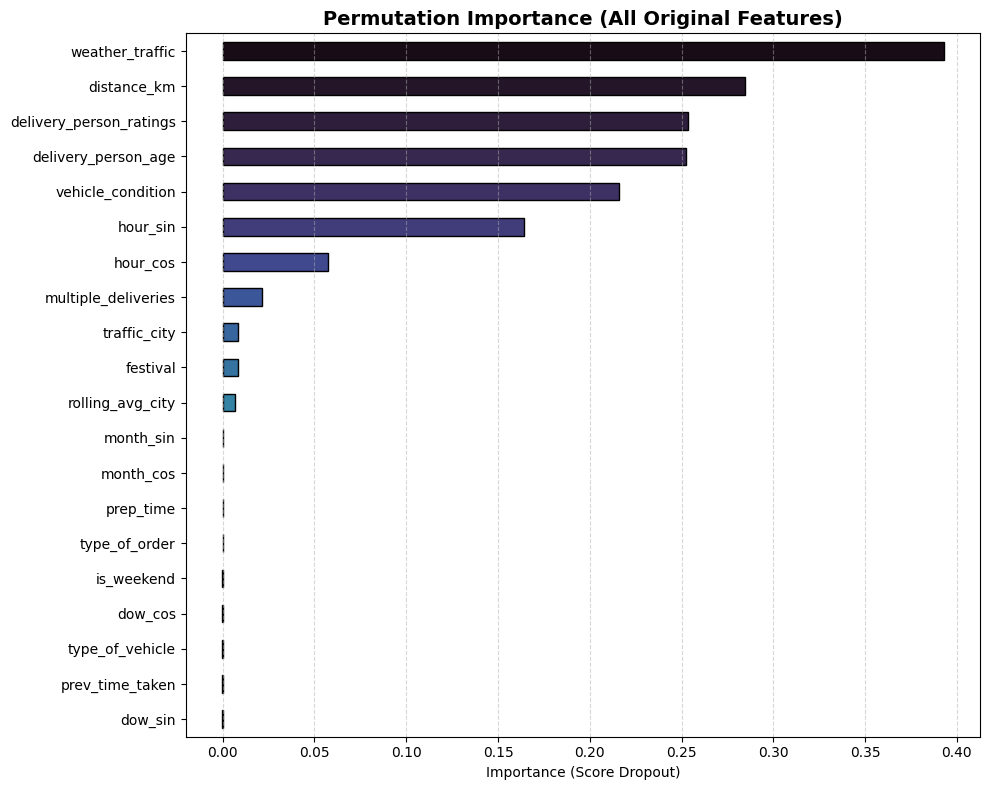

In [ ]:
from sklearn.inspection import permutation_importance

# =========================
# 🔥 2. Permutation Importance TRÊN PIPELINE
# (Tự động tính importance theo biến gốc)
# =========================
print("🚀 Đang tính Permutation Importance trên Pipeline (có thể mất vài phút)...")
perm_result = permutation_importance(
    rf_best,      # Dùng cả Pipeline
    X_test,       # Dùng dữ liệu gốc
    y_test,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Kết quả theo tên cột gốc
final_perm_imp = pd.Series(
    perm_result.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

# 3. Vẽ biểu đồ
plt.figure(figsize=(10, 8)) # Tăng chiều cao để đủ chỗ cho tất cả biến
colors = sns.color_palette("mako", len(final_perm_imp))

final_perm_imp.plot( # Vẽ tất cả các biến
    kind='barh',
    color=colors,
    edgecolor='black'
)

plt.gca().invert_yaxis()
plt.title("Permutation Importance (All Original Features)",
          fontsize=14,
          fontweight='bold')
plt.xlabel("Importance (Score Dropout)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

path = "/content/drive/Shareddrives/5 CÔ GÁI/NĂM 3/KÌ 2/PTDLNC/ĐỒ ÁN/MODEL/random_forest_final_model.pkl"

joblib.dump(rf_best, path)
rf_loaded = joblib.load(path)

y_pred_loaded = rf_loaded.predict(X_test)
print("✅ Đã load model Random Forest thành công")

✅ Đã load model Random Forest thành công
